# Análise exploratória: Telco Customer Churn

Objetivo: entender volume, qualidade e distribuição dos dados antes da modelagem. A exploração fica aqui; o código de produção está em `src/churn/`.

# Análise exploratória: Telco Customer Churn

Objetivo: entender volume, qualidade e distribuição dos dados antes da modelagem. A exploração fica aqui; o código de produção está em `src/churn/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [4]:
print(f"Linhas {df.shape[0]} | Colunas {df.shape[1]}")
df.head()

Linhas 7043 | Colunas 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.sample(8, random_state=7)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6632,9259-PACGQ,Female,0,Yes,No,34,Yes,Yes,DSL,Yes,...,No,Yes,No,No,Month-to-month,No,Electronic check,62.65,2274.9,Yes
3801,5914-DVBWJ,Female,1,No,No,18,Yes,Yes,Fiber optic,No,...,No,Yes,No,No,Month-to-month,Yes,Electronic check,85.45,1505.85,Yes
901,9734-YWGEX,Female,0,No,No,9,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,No,Credit card (automatic),98.30,923.5,Yes
1487,5035-PGZXH,Female,0,No,No,56,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Electronic check,106.80,5914.4,No
1457,6362-QHAFM,Male,0,Yes,No,42,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,One year,Yes,Electronic check,108.30,4586.15,No
131,6207-WIOLX,Female,0,Yes,Yes,25,No,No phone service,DSL,Yes,...,Yes,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),58.60,1502.65,Yes
985,9369-XFEHK,Female,1,Yes,No,33,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),80.60,2656.5,Yes
4916,3420-YJLQT,Female,0,No,No,2,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,No,Electronic check,79.55,151.75,No


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 1. Qualidade dos dados

In [7]:
blank_total = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print("Linhas duplicadas:", df.duplicated().sum())
print("customerID repetidos:", df["customerID"].duplicated().sum())
print("Nulos declarados:", df.isna().sum().sum())
print("TotalCharges não numérico:", blank_total.sum())
df.loc[blank_total, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Linhas duplicadas: 0
customerID repetidos: 0
Nulos declarados: 0
TotalCharges não numérico: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


**Leitura.** Não há duplicatas nem nulos declarados. O único problema está em `TotalCharges`: a coluna é texto e tem 11 valores em branco, todos de clientes com `tenure = 0`, ou seja, que ainda não receberam cobrança.

**Decisão.** Preencher com 0, pois esse é o valor real, e não com a mediana. A regra está em `churn.data.clean_features` e vale para treino e API.

In [8]:
from churn.data import load_dataset

X, y = load_dataset()
data = X.assign(churn=y)
print(f"Taxa de churn: {y.mean():.1%} ({y.sum()} de {len(y)} clientes)")
X.describe().round(1)

Taxa de churn: 26.5% (1869 de 7043 clientes)


,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7043.0
mean,32.4,64.8,2279.7
std,24.6,30.1,2266.8
min,0.0,18.2,0.0
25%,9.0,35.5,398.6
50%,29.0,70.4,1394.6
75%,55.0,89.8,3786.6
max,72.0,118.8,8684.8


**Leitura.** O alvo é moderadamente desbalanceado (26,5% de churn). Por isso, acurácia não serve como métrica: um modelo que nunca prevê churn já acertaria 73,5%.

## 2. Variáveis numéricas

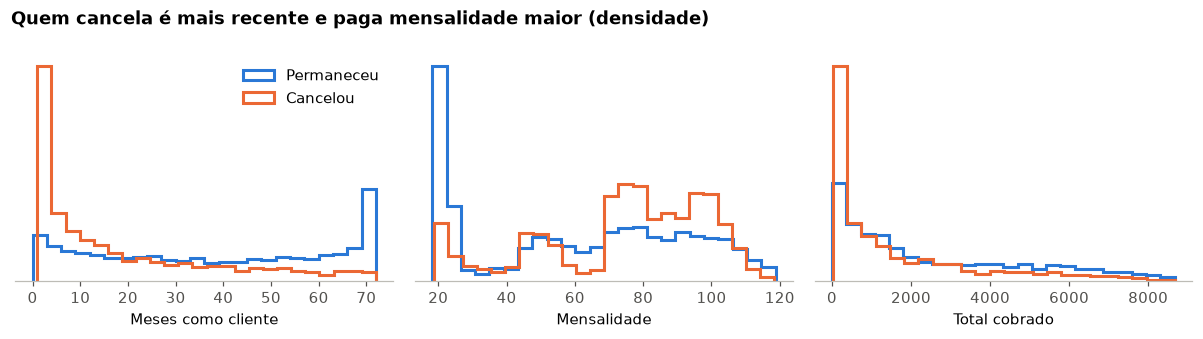

In [9]:
import matplotlib.pyplot as plt

NO_CHURN, CHURN, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#bdbcb6", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": "#e8e7e3",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.axisbelow": True,
})

columns = {"tenure": "Meses como cliente", "MonthlyCharges": "Mensalidade",
           "TotalCharges": "Total cobrado"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1))
for ax, (column, label) in zip(axes, columns.items()):
    bins = 24
    ax.hist(data.loc[data.churn == 0, column], bins=bins, histtype="step", linewidth=2,
            color=NO_CHURN, density=True, label="Permaneceu")
    ax.hist(data.loc[data.churn == 1, column], bins=bins, histtype="step", linewidth=2,
            color=CHURN, density=True, label="Cancelou")
    ax.set_xlabel(label)
    ax.set_yticks([])
    ax.grid(False)
axes[0].legend(frameon=False)
fig.suptitle("Quem cancela é mais recente e paga mensalidade maior (densidade)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../docs/figures/numeric_distributions.png")
plt.show()

In [10]:
print(data.groupby("churn")[list(columns)].median().round(1))
data[[*columns, "churn"]].corr().round(2)

       tenure  MonthlyCharges  TotalCharges
churn                                      
0        38.0            64.4        1679.5
1        10.0            79.6         703.6


,tenure,MonthlyCharges,TotalCharges,churn
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
churn,-0.35,0.19,-0.20,1.00


**Leitura.**

- A mediana de `tenure` é de 10 meses entre quem cancela e de 38 entre quem fica.
- A mediana de `MonthlyCharges` é 79,65 contra 64,43.
- `tenure` e `TotalCharges` têm correlação de 0,83, pois o total é aproximadamente mensalidade × meses. A redundância é tolerável para os modelos usados, mas impede interpretar os coeficientes dessas colunas de forma isolada.

## 3. Taxa de churn por categoria

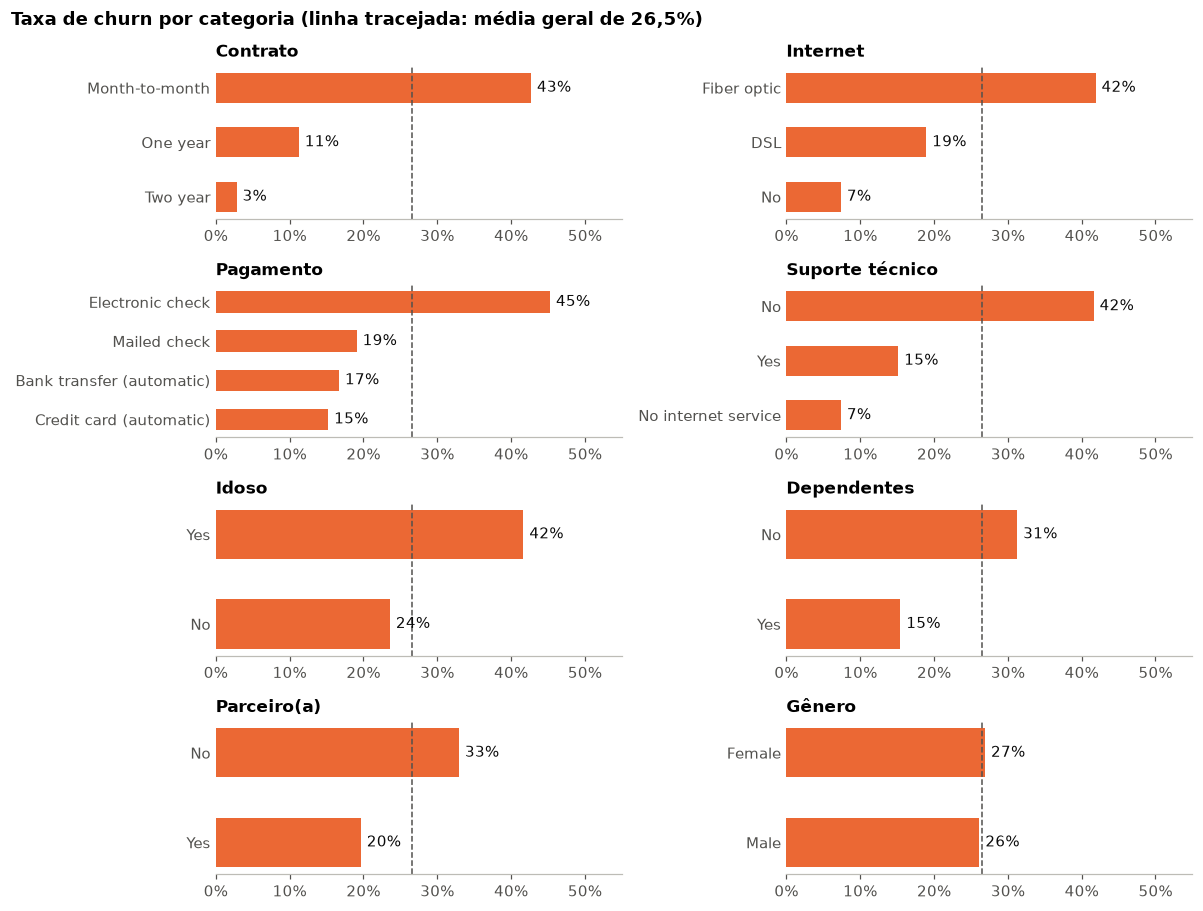

In [11]:
panels = {
    "Contract": "Contrato", "InternetService": "Internet",
    "PaymentMethod": "Pagamento", "TechSupport": "Suporte técnico",
    "SeniorCitizen": "Idoso", "Dependents": "Dependentes", "Partner": "Parceiro(a)",
    "gender": "Gênero",
}
fig, axes = plt.subplots(4, 2, figsize=(11, 8.4))
for ax, (column, title) in zip(axes.ravel(), panels.items()):
    rates = data.groupby(column)["churn"].mean().sort_values()
    ax.barh(rates.index, rates.values, color=CHURN, height=0.55)
    ax.axvline(y.mean(), color=MUTED, linewidth=1, linestyle="--")
    for position, value in enumerate(rates.values):
        ax.text(value + 0.008, position, f"{value:.0%}", va="center", color="#0b0b0b")
    ax.set_title(title)
    ax.set_xlim(0, 0.55)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.grid(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle("Taxa de churn por categoria (linha tracejada: média geral de 26,5%)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../docs/figures/churn_by_category.png")
plt.show()

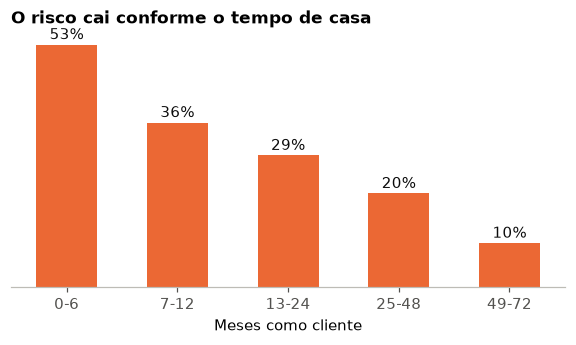

,mean,size
tenure,,
0-6,0.529,1481
7-12,0.359,705
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


In [12]:
bands = pd.cut(data["tenure"], [-1, 6, 12, 24, 48, 72],
              labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
by_band = data.groupby(bands, observed=True)["churn"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(by_band.index.astype(str), by_band["mean"], color=CHURN, width=0.55)
for position, value in enumerate(by_band["mean"]):
    ax.text(position, value + 0.012, f"{value:.0%}", ha="center", color="#0b0b0b")
ax.set_title("O risco cai conforme o tempo de casa")
ax.set_xlabel("Meses como cliente")
ax.set_yticks([])
ax.grid(False)
fig.savefig("../docs/figures/churn_by_tenure.png")
plt.show()
by_band.round(3)

**Leitura.**

- **Contrato** é o maior separador: 43% no mês a mês, 11% no anual e 3% no bienal. O mês a mês representa 55% da base.
- **Tempo de casa**: 53% de churn nos 6 primeiros meses e 10% após 4 anos.
- **Fibra óptica** (42%) e **boleto eletrônico** (45%) concentram churn. A fibra merece investigação de preço e qualidade, já que a mensalidade é mais alta.
- **Sem suporte técnico** (42%) ou sem segurança online (42%), o churn é cerca de 2,8 vezes o de quem tem esses serviços (15%).
- **Gênero** praticamente não separa (27% e 26%). **Idosos** cancelam bem mais (42% contra 24%), ponto acompanhado na análise de vieses do Model Card.

Esses números são associações, não causas: o dataset é observacional.

## 4. Implicações para a modelagem

| Achado | Decisão |
|---|---|
| 26,5% de churn | Medir com AUC-ROC e PR-AUC, nunca acurácia |
| Custo de erro assimétrico | Escolher o limiar pelo valor de negócio, não 0,5 |
| 16 categóricas com poucas categorias | One-hot, sem explosão de dimensionalidade |
| Escalas numéricas diferentes | Padronizar, necessário para logística e MLP |
| Categorias como `No internet service` | Manter: são estados válidos do cliente |
| `customerID` | Remover: é identificador, sem valor preditivo legítimo |


## 1. Qualidade dos dados

In [13]:
blank_total = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print("Linhas duplicadas:", df.duplicated().sum())
print("customerID repetidos:", df["customerID"].duplicated().sum())
print("Nulos declarados:", df.isna().sum().sum())
print("TotalCharges não numérico:", blank_total.sum())
df.loc[blank_total, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Linhas duplicadas: 0
customerID repetidos: 0
Nulos declarados: 0
TotalCharges não numérico: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


**Leitura.** Não há duplicatas nem nulos declarados. O único problema está em `TotalCharges`: a coluna é texto e tem 11 valores em branco, todos de clientes com `tenure = 0`, ou seja, que ainda não receberam cobrança.

**Decisão.** Preencher com 0, pois esse é o valor real, e não com a mediana. A regra está em `churn.data.clean_features` e vale para treino e API.

In [14]:
from churn.data import load_dataset

X, y = load_dataset()
data = X.assign(churn=y)
print(f"Taxa de churn: {y.mean():.1%} ({y.sum()} de {len(y)} clientes)")
X.describe().round(1)

Taxa de churn: 26.5% (1869 de 7043 clientes)


,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7043.0
mean,32.4,64.8,2279.7
std,24.6,30.1,2266.8
min,0.0,18.2,0.0
25%,9.0,35.5,398.6
50%,29.0,70.4,1394.6
75%,55.0,89.8,3786.6
max,72.0,118.8,8684.8


**Leitura.** O alvo é moderadamente desbalanceado (26,5% de churn). Por isso, acurácia não serve como métrica: um modelo que nunca prevê churn já acertaria 73,5%.

## 2. Variáveis numéricas

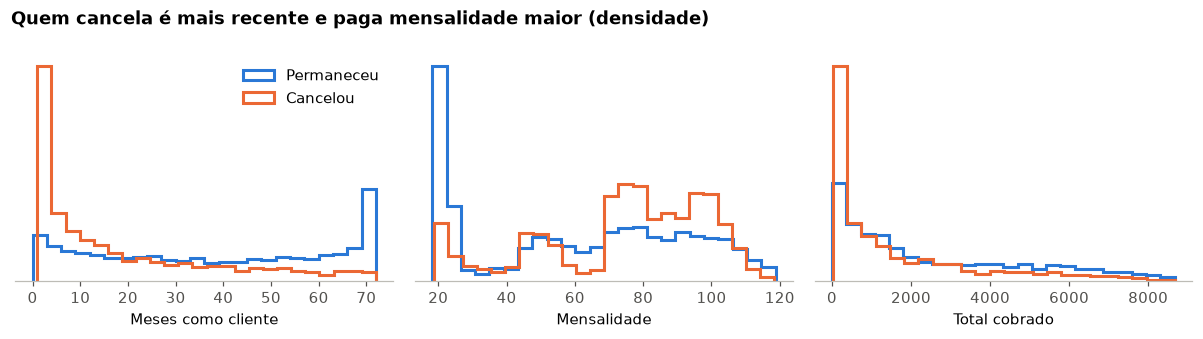

In [15]:
import matplotlib.pyplot as plt

NO_CHURN, CHURN, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#bdbcb6", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": "#e8e7e3",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.axisbelow": True,
})

columns = {"tenure": "Meses como cliente", "MonthlyCharges": "Mensalidade",
           "TotalCharges": "Total cobrado"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1))
for ax, (column, label) in zip(axes, columns.items()):
    bins = 24
    ax.hist(data.loc[data.churn == 0, column], bins=bins, histtype="step", linewidth=2,
            color=NO_CHURN, density=True, label="Permaneceu")
    ax.hist(data.loc[data.churn == 1, column], bins=bins, histtype="step", linewidth=2,
            color=CHURN, density=True, label="Cancelou")
    ax.set_xlabel(label)
    ax.set_yticks([])
    ax.grid(False)
axes[0].legend(frameon=False)
fig.suptitle("Quem cancela é mais recente e paga mensalidade maior (densidade)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../docs/figures/numeric_distributions.png")
plt.show()

In [16]:
print(data.groupby("churn")[list(columns)].median().round(1))
data[[*columns, "churn"]].corr().round(2)

       tenure  MonthlyCharges  TotalCharges
churn                                      
0        38.0            64.4        1679.5
1        10.0            79.6         703.6


,tenure,MonthlyCharges,TotalCharges,churn
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
churn,-0.35,0.19,-0.20,1.00


**Leitura.**

- A mediana de `tenure` é de 10 meses entre quem cancela e de 38 entre quem fica.
- A mediana de `MonthlyCharges` é 79,65 contra 64,43.
- `tenure` e `TotalCharges` têm correlação de 0,83, pois o total é aproximadamente mensalidade × meses. A redundância é tolerável para os modelos usados, mas impede interpretar os coeficientes dessas colunas de forma isolada.

## 3. Taxa de churn por categoria

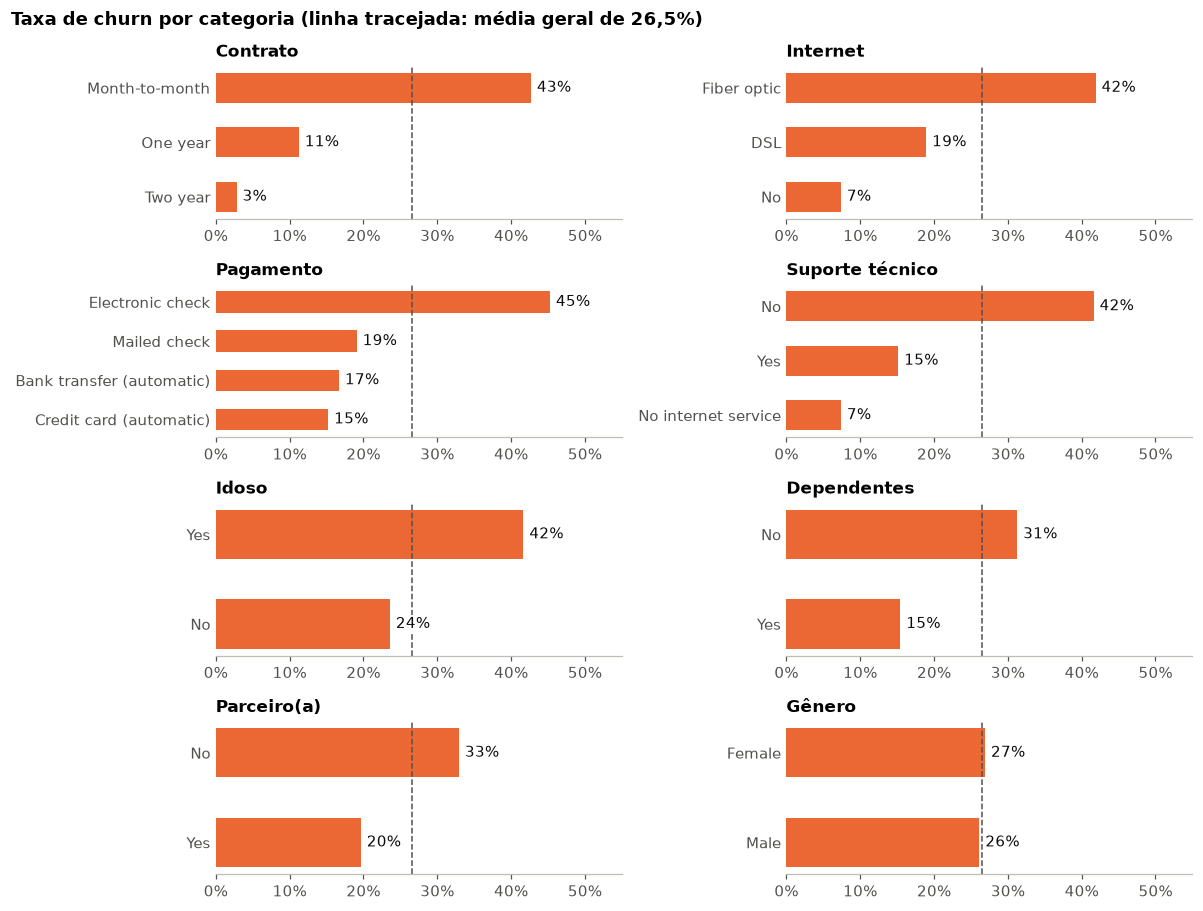

In [17]:
panels = {
    "Contract": "Contrato", "InternetService": "Internet",
    "PaymentMethod": "Pagamento", "TechSupport": "Suporte técnico",
    "SeniorCitizen": "Idoso", "Dependents": "Dependentes", "Partner": "Parceiro(a)",
    "gender": "Gênero",
}
fig, axes = plt.subplots(4, 2, figsize=(11, 8.4))
for ax, (column, title) in zip(axes.ravel(), panels.items()):
    rates = data.groupby(column)["churn"].mean().sort_values()
    ax.barh(rates.index, rates.values, color=CHURN, height=0.55)
    ax.axvline(y.mean(), color=MUTED, linewidth=1, linestyle="--")
    for position, value in enumerate(rates.values):
        ax.text(value + 0.008, position, f"{value:.0%}", va="center", color="#0b0b0b",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_title(title)
    ax.set_xlim(0, 0.55)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.grid(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle("Taxa de churn por categoria (linha tracejada: média geral de 26,5%)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../docs/figures/churn_by_category.png")
plt.show()

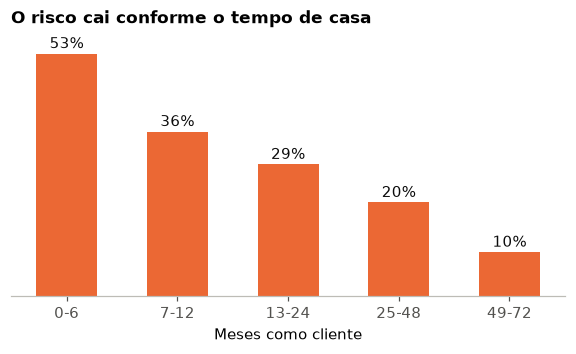

,mean,size
tenure,,
0-6,0.529,1481
7-12,0.359,705
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


In [18]:
bands = pd.cut(data["tenure"], [-1, 6, 12, 24, 48, 72],
              labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
by_band = data.groupby(bands, observed=True)["churn"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(by_band.index.astype(str), by_band["mean"], color=CHURN, width=0.55)
for position, value in enumerate(by_band["mean"]):
    ax.text(position, value + 0.012, f"{value:.0%}", ha="center", color="#0b0b0b")
ax.set_title("O risco cai conforme o tempo de casa", pad=12)
ax.set_xlabel("Meses como cliente")
ax.set_yticks([])
ax.grid(False)
fig.savefig("../docs/figures/churn_by_tenure.png")
plt.show()
by_band.round(3)

**Leitura.**

- **Contrato** é o maior separador: 43% no mês a mês, 11% no anual e 3% no bienal. O mês a mês representa 55% da base.
- **Tempo de casa**: 53% de churn nos 6 primeiros meses e 10% após 4 anos.
- **Fibra óptica** (42%) e **cheque eletrônico** (45%) concentram churn. A fibra merece investigação de preço e qualidade, já que a mensalidade é mais alta.
- **Sem suporte técnico** (42%) ou sem segurança online (42%), o churn é cerca de 2,8 vezes o de quem tem esses serviços (15%).
- **Gênero** praticamente não separa (27% e 26%). **Idosos** cancelam bem mais (42% contra 24%), ponto acompanhado na análise de vieses do Model Card.

Esses números são associações, não causas: o dataset é observacional.

## 4. Implicações para a modelagem

| Achado | Decisão |
|---|---|
| 26,5% de churn | Medir com AUC-ROC e PR-AUC, nunca acurácia |
| Custo de erro assimétrico | Escolher o limiar pelo valor de negócio, não 0,5 |
| 16 categóricas com poucas categorias | One-hot, sem explosão de dimensionalidade |
| Escalas numéricas diferentes | Padronizar, necessário para logística e MLP |
| Categorias como `No internet service` | Manter: são estados válidos do cliente |
| `customerID` | Remover: é identificador, sem valor preditivo legítimo |
